# Logistic regression from scratch
Implementation and explanations by Alejandro.

In [97]:
import numpy as np
import pandas as pd

df_cancer = pd.read_csv("../data/breast_cancer.csv")


df_cancer.info()
df_cancer.describe()
df_cancer.head()


<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   radius_mean              569 non-null    float64
 1   texture_mean             569 non-null    float64
 2   perimeter_mean           569 non-null    float64
 3   area_mean                569 non-null    float64
 4   smoothness_mean          569 non-null    float64
 5   compactness_mean         569 non-null    float64
 6   concavity_mean           569 non-null    float64
 7   concave_points_mean      569 non-null    float64
 8   symmetry_mean            569 non-null    float64
 9   fractal_dimension_mean   569 non-null    float64
 10  radius_se                569 non-null    float64
 11  texture_se               569 non-null    float64
 12  perimeter_se             569 non-null    float64
 13  area_se                  569 non-null    float64
 14  smoothness_se            569 non-null

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [98]:
df_cancer.corr()#using all data which is wrong

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,fractal_dimension_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst,target
radius_mean,1.000000,0.323782,0.997855,0.987357,0.170581,0.506124,0.676764,0.822529,0.147741,-0.311631,...,0.297008,0.965137,0.941082,0.119616,0.413463,0.526911,0.744214,0.163953,0.007066,-0.730029
texture_mean,0.323782,1.000000,0.329533,0.321086,-0.023389,0.236702,0.302418,0.293464,0.071401,-0.076437,...,0.912045,0.358040,0.343546,0.077503,0.277830,0.301025,0.295316,0.105008,0.119205,-0.415185
perimeter_mean,0.997855,0.329533,1.000000,0.986507,0.207278,0.556936,0.716136,0.850977,0.183027,-0.261477,...,0.303038,0.970387,0.941550,0.150549,0.455774,0.563879,0.771241,0.189115,0.051019,-0.742636
area_mean,0.987357,0.321086,0.986507,1.000000,0.177028,0.498502,0.685983,0.823269,0.151293,-0.283110,...,0.287489,0.959120,0.959213,0.123523,0.390410,0.512606,0.722017,0.143570,0.003738,-0.708984
smoothness_mean,0.170581,-0.023389,0.207278,0.177028,1.000000,0.659123,0.521984,0.553695,0.557775,0.584792,...,0.036072,0.238853,0.206718,0.805324,0.472468,0.434926,0.503053,0.394309,0.499316,-0.358560
compactness_mean,0.506124,0.236702,0.556936,0.498502,0.659123,1.000000,0.883121,0.831135,0.602641,0.565369,...,0.248133,0.590210,0.509604,0.565541,0.865809,0.816275,0.815573,0.510223,0.687382,-0.596534
concavity_mean,0.676764,0.302418,0.716136,0.685983,0.521984,0.883121,1.000000,0.921391,0.500667,0.336783,...,0.299879,0.729565,0.675987,0.448822,0.754968,0.884103,0.861323,0.409464,0.514930,-0.696360
concave_points_mean,0.822529,0.293464,0.850977,0.823269,0.553695,0.831135,0.921391,1.000000,0.462497,0.166917,...,0.292752,0.855923,0.809630,0.452753,0.667454,0.752399,0.910155,0.375744,0.368661,-0.776614
symmetry_mean,0.147741,0.071401,0.183027,0.151293,0.557775,0.602641,0.500667,0.462497,1.000000,0.479921,...,0.090651,0.219169,0.177193,0.426675,0.473200,0.433721,0.430297,0.699826,0.438413,-0.330499
fractal_dimension_mean,-0.311631,-0.076437,-0.261477,-0.283110,0.584792,0.565369,0.336783,0.166917,0.479921,1.000000,...,-0.051269,-0.205151,-0.231854,0.504942,0.458798,0.346234,0.175325,0.334019,0.767297,0.012838


In [99]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Chose the ones that seem the highest correlation
SELECTED_COLUMNS=[
# "radius_mean",
# "texture_mean",
"perimeter_mean",
"area_mean",
# "smoothness_mean",
# "compactness_mean",
# "concavity_mean",
"concave_points_mean",
# "symmetry_mean",
# "fractal_dimension_mean",
# "radius_se",
# "texture_se",
# "perimeter_se",
# "area_se",
# "smoothness_se",
# "compactness_se",
# "concavity_se",
# "concave_points_se",
# "symmetry_se",
# "fractal_dimension_se",
"radius_worst",
# "texture_worst",
"perimeter_worst",
"area_worst",
# "smoothness_worst",
# "compactness_worst",
# "concavity_worst",
# "concave_points_worst",
# "symmetry_worst",
# "fractal_dimension_worst",
]
SELECTED_TARGET = ['target']
display(df_cancer[SELECTED_COLUMNS].corr())
X_train, X_test, y_train, y_test = train_test_split(df_cancer[SELECTED_COLUMNS].to_numpy(), df_cancer[SELECTED_TARGET].to_numpy(), test_size=.2)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

,perimeter_mean,area_mean,concave_points_mean,radius_worst,perimeter_worst,area_worst
perimeter_mean,1.000000,0.986507,0.850977,0.969476,0.970387,0.941550
area_mean,0.986507,1.000000,0.823269,0.962746,0.959120,0.959213
concave_points_mean,0.850977,0.823269,1.000000,0.830318,0.855923,0.809630
radius_worst,0.969476,0.962746,0.830318,1.000000,0.993708,0.984015
perimeter_worst,0.970387,0.959120,0.855923,0.993708,1.000000,0.977578
area_worst,0.941550,0.959213,0.809630,0.984015,0.977578,1.000000


# create LR Class

In [109]:

def sigmoid(x):
    return 1 / (1 + np.exp(-x))
# sigmoid = np.vectorize(sigmoid)

rng = np.random.default_rng(seed=42)

class NeuronLogisticRegression():
    def __init__(self, feature_count, lr = 0.1):
       self.W = rng.normal(loc=0,scale=1,size=(1, feature_count)) * 0.1#np.zeros(feature_count)
       self.B = rng.normal(loc=0,scale=1,size=(1, 1)) * 0.1 #0
       self.lr = lr
        #    self.inputs = np.zeros(feature_count)
    
    def feedforward(self, X):
        #   (1, nx) @ (m, nx) + (1, 1)
        Z = self.W @ X.T + self.B

        # print(Z.shape, self.W.shape, X.T.shape, self.B.shape)
        A = sigmoid(Z)
        # cache a, z not needed in this case 
        return A,Z

    def cost(self, A, Y, m):
        return np.sum(-(Y *  np.log(np.clip(A,0.00001,1)) + (1 - Y)* np.log(np.clip(1 - A,0.00001,1))),axis=1)/m


    def backwards(self, A, X, Y):
        m = len(X)
        # print(X.shape, A.shape, Y.T.shape)
        # (1,m)
        dz = A - Y.T
        # (1,m) @ (m,nx)
        dw = dz @ X / m
        db = np.sum(dz) / m
        return dw, db

        
    def update(self, dw,db):
        self.W = self.W - self.lr * dw
        self.B = self.B - self.lr * db

    def fit(self, X, Y, epoch=1000): 
        self.cost_values = []
        for e in range(epoch):
            A,Z = self.feedforward(X)
            self.cost_values.append(self.cost(A,Y.T,len(X)))
            # if e % 100 == 0:
                # print(np.max(Z),np.max(A))
                # print(np.min(Z),np.min(A))
                # print(e%100,self.cost(A,Y.T, len(X)))
            dw,db = self.backwards(A,X,Y)
            self.update(dw,db)
    


        

nlr = NeuronLogisticRegression(len(SELECTED_COLUMNS))

print(X_train.shape, y_train.shape)

nlr.fit(X_train,y_train)
A,Z = nlr.feedforward(X_train)
THRESHOLD = 0.5
print("accuracy", np.sum(
     (A.T > THRESHOLD) == y_train)/
      len(y_train) * 100)

#TEST
A,Z = nlr.feedforward(X_test)

THRESHOLD = 0.5
print("accuracy", np.sum(
     (A.T > THRESHOLD) == y_test)/
      len(y_test) * 100)


(455, 6) (455, 1)
accuracy 92.96703296703296
accuracy 95.6140350877193


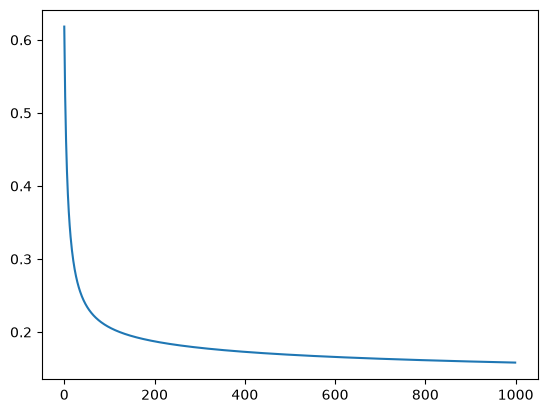

In [101]:
import matplotlib.pyplot as plt

plt.plot(nlr.cost_values)

# Gradient checking

In [135]:
A,Z = nlr.feedforward(X_train)

original_W = nlr.W.copy()
original_slope = nlr.backwards(A,X_train,y_train)
original_cost = nlr.cost(A,y_train.T,len(X_train))

nlr.W[0,0] *= 0.99

A,Z = nlr.feedforward(X_train)
changed_slopes = nlr.backwards(A,X_train,y_train)

delta_in_loss = original_cost - nlr.cost(A, y_train.T, len(X_train))
delta_in_w = original_W[0,0] - nlr.W[0,0]

experimental_slope = delta_in_loss/delta_in_w

analytical_slope = changed_slopes[0][0,0]

print(f'Slopes experimental: {experimental_slope}')
print(f'Analytical: {analytical_slope}')
print(f'diff 1% change experimental:{experimental_slope-analytical_slope}')
print(f'diff with original:{experimental_slope-original_slope[0][0,0]}')



# display(original_cost , nlr.cost(A, y_train.T, len(X_train)), original_W[0,0] , changed_slopes[0][0])
nlr.W = original_W

Slopes experimental: [-0.00601695]
Analytical: -0.006015639914255372
diff 1% change experimental:[-1.30589009e-06]
diff with original:[1.30582693e-06]
